# Bab 11 – Novelty and Outlier Detection

## Ringkasan Bab
**Outlier detection** mencari data yang menyimpang dalam data latih, sedangkan **novelty detection** melatih model pada data yang
"bersih" lalu menilai apakah data baru tergolong normal. Bab ini membahas **Isolation Forest**, **One-Class SVM**, **Local Outlier Factor (LOF)**,
**Elliptic Envelope**, cara evaluasi, dan cara menangani outlier yang ditemukan.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.datasets import make_blobs, load_breast_cancer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_fscore_support
rng = np.random.default_rng(42)
# Data sintetis: 2 gerombolan normal + outlier acak (label: 1 = normal, -1 = outlier)
Xn, _ = make_blobs(n_samples=470, centers=[[0, 0], [5, 5]], cluster_std=.8, random_state=0)
Xo = rng.uniform(-4, 9, (30, 2))
X = np.vstack([Xn, Xo]); y = np.r_[np.ones(470), -np.ones(30)]

## 1. Pengantar Deteksi Outlier dan Novelty
| | Outlier detection | Novelty detection |
|---|---|---|
| Data latih | sudah mengandung outlier | dianggap bersih (hanya normal) |
| Tujuan | menandai outlier di data latih | menilai data **baru** |
| Metode sklearn | `fit_predict` | `fit` lalu `predict` |

Penyebab outlier: kesalahan input, kerusakan sensor, kejadian langka yang sah (penipuan, kerusakan mesin).
Karena outlier jarang, label hampir tidak tersedia, sehingga metode *unsupervised* dipakai.

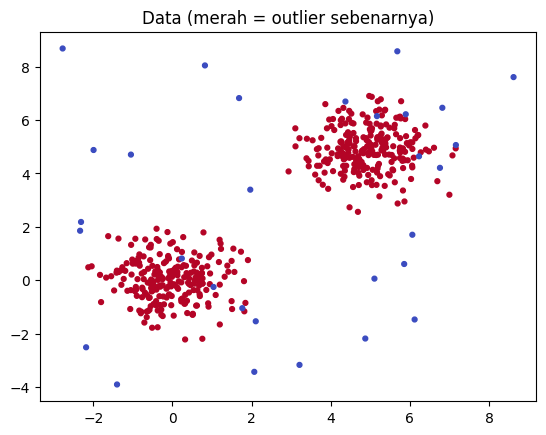

In [2]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12); plt.title("Data (merah = outlier sebenarnya)"); plt.show()

## 2. Isolation Forest
Ide: outlier **mudah diisolasi**. Pohon acak membagi data dengan fitur dan ambang acak; titik anomali cukup dipisahkan dengan sedikit
pembagian (jalur pendek). Skor anomali dihitung dari rata-rata panjang jalur di banyak pohon. Cepat, tidak perlu scaling,
dan baik untuk data berdimensi tinggi. Parameter penting: `contamination` (perkiraan proporsi outlier).

In [3]:
iso = IsolationForest(n_estimators=200, contamination=0.06, random_state=0).fit(X)
pred = iso.predict(X)
print(classification_report(y, pred, target_names=["outlier", "normal"]))
print("AUC skor anomali:", round(roc_auc_score(y == -1, -iso.score_samples(X)), 3))

              precision    recall  f1-score   support

     outlier       0.73      0.73      0.73        30
      normal       0.98      0.98      0.98       470

    accuracy                           0.97       500
   macro avg       0.86      0.86      0.86       500
weighted avg       0.97      0.97      0.97       500

AUC skor anomali: 0.941


## 3. One-Class SVM
Dipelajari batas yang mengelilingi data normal di ruang kernel, dengan parameter `nu` (batas atas proporsi outlier dan batas bawah proporsi
support vector) dan `gamma`. Cocok untuk **novelty detection** pada data kecil sampai menengah, tetapi peka terhadap scaling dan pemilihan `gamma`.

In [4]:
Xs = StandardScaler().fit(Xn).transform(X)
oc = OneClassSVM(kernel="rbf", nu=.05, gamma=.3).fit(StandardScaler().fit_transform(Xn))
p_oc = oc.predict(Xs)
print("One-Class SVM (dilatih hanya pada data normal):")
print(classification_report(y, p_oc, target_names=["outlier", "normal"]))

One-Class SVM (dilatih hanya pada data normal):
              precision    recall  f1-score   support

     outlier       0.51      0.80      0.62        30
      normal       0.99      0.95      0.97       470

    accuracy                           0.94       500
   macro avg       0.75      0.88      0.80       500
weighted avg       0.96      0.94      0.95       500



## 4. Local Outlier Factor (LOF)
LOF membandingkan **kepadatan lokal** suatu titik dengan kepadatan tetangganya. Titik dengan kepadatan jauh lebih rendah daripada tetangganya
mendapat skor LOF > 1 dan dianggap outlier. Kelebihan: bisa mendeteksi outlier lokal pada data dengan kepadatan beragam.
Dengan `novelty=False` (default) hanya ada `fit_predict`; untuk data baru gunakan `novelty=True`.

In [5]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=.06)
p_lof = lof.fit_predict(X)
print("LOF:"); print(classification_report(y, p_lof, target_names=["outlier", "normal"]))
lof_nov = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Xn)
print("Prediksi LOF novelty untuk titik (0,0) dan (20,20):", lof_nov.predict([[0, 0], [20, 20]]))

LOF:
              precision    recall  f1-score   support

     outlier       0.70      0.70      0.70        30
      normal       0.98      0.98      0.98       470

    accuracy                           0.96       500
   macro avg       0.84      0.84      0.84       500
weighted avg       0.96      0.96      0.96       500

Prediksi LOF novelty untuk titik (0,0) dan (20,20): [ 1 -1]


## 5. Mengevaluasi Model Deteksi Outlier
Jika ada label (seperti pada data simulasi ini), gunakan **precision, recall, F1 untuk kelas outlier** dan **ROC-AUC** dari skor anomali.
Jangan memakai akurasi, karena kelas sangat tidak seimbang (menebak "semua normal" sudah akurasi 94%).
Tanpa label, nilai hasilnya secara visual dan lewat pemeriksaan manual oleh ahli domain.

In [6]:
models = {"IsolationForest": (iso, -iso.score_samples(X)), "OneClassSVM": (oc, -oc.score_samples(Xs)),
          "LOF": (lof, -lof.negative_outlier_factor_), "EllipticEnvelope": None}
ee = EllipticEnvelope(contamination=.06, random_state=0).fit(X); models["EllipticEnvelope"] = (ee, -ee.score_samples(X))
rows = []
for n, (m, s) in models.items():
    pr = {"IsolationForest": pred, "OneClassSVM": p_oc, "LOF": p_lof, "EllipticEnvelope": ee.predict(X)}[n]
    p, r, f, _ = precision_recall_fscore_support(y == -1, pr == -1, average="binary")
    rows.append({"metode": n, "precision": p, "recall": r, "F1": f, "AUC": roc_auc_score(y == -1, s)})
pd.DataFrame(rows).round(3)

,metode,precision,recall,F1,AUC
0,IsolationForest,0.733,0.733,0.733,0.941
1,OneClassSVM,0.511,0.800,0.623,0.934
2,LOF,0.700,0.700,0.700,0.932
3,EllipticEnvelope,0.600,0.600,0.600,0.900


## 6. Menangani Outlier yang Terdeteksi
Jangan langsung membuang! Periksa dulu apakah itu kesalahan data atau kejadian penting. Pilihan penanganan:
1. **Hapus** (jika terbukti salah input).
2. **Winsorizing/clipping** ke persentil tertentu.
3. **Transformasi** (log) atau **scaler yang robust** (`RobustScaler`).
4. **Pakai model yang robust** terhadap outlier, atau simpan sebagai fitur "is_outlier".
5. **Pertahankan dan pelajari** bila tujuannya justru menemukan anomali.

In [7]:
xx = np.r_[rng.normal(10, 1, 200), [40, 45]]; yy = 2 * xx + rng.normal(0, 1, 202); yy[-2:] = [10, 12]
for name, mask in [("dengan outlier", np.ones(202, bool)), ("tanpa outlier", np.r_[np.ones(200, bool), [False, False]])]:
    print(f"Slope regresi {name}: {LinearRegression().fit(xx[mask, None], yy[mask]).coef_[0]:.2f}  (nilai sebenarnya = 2)")
lo, hi = np.percentile(xx, [1, 99]); print("Setelah winsorizing, maksimum:", np.clip(xx, lo, hi).max().round(2))

Slope regresi dengan outlier: -0.08  (nilai sebenarnya = 2)
Slope regresi tanpa outlier: 2.02  (nilai sebenarnya = 2)
Setelah winsorizing, maksimum: 12.91


## 7. Memilih Teknik yang Tepat
| Metode | Kekuatan | Kelemahan |
|---|---|---|
| Isolation Forest | cepat, skalabel, dimensi tinggi | kurang peka terhadap outlier lokal |
| One-Class SVM | batas fleksibel, novelty detection | lambat di data besar, peka `gamma`/`nu` |
| LOF | outlier lokal, kepadatan beragam | lambat di data besar, peka `n_neighbors` |
| Elliptic Envelope | cepat, sederhana | mengasumsikan data berdistribusi Gaussian |

## 8. Latihan Praktik

### Latihan 1 – Isolation Forest pada Data Dunia Nyata
Dataset kanker payudara: kelas "malignant" yang jarang dijadikan sebagai "anomali" dengan mengurangi jumlahnya.

In [8]:
Xc, yc = load_breast_cancer(return_X_y=True)
mal = np.where(yc == 0)[0][:15]; ben = np.where(yc == 1)[0]
idx = np.r_[ben, mal]; Xr, yr = StandardScaler().fit_transform(Xc[idx]), np.where(yc[idx] == 0, -1, 1)
isoc = IsolationForest(n_estimators=300, contamination=len(mal)/len(idx), random_state=0).fit(Xr)
print("AUC:", round(roc_auc_score(yr == -1, -isoc.score_samples(Xr)), 3))
print(classification_report(yr, isoc.predict(Xr), target_names=["anomali", "normal"]))

AUC: 0.969
              precision    recall  f1-score   support

     anomali       0.53      0.53      0.53        15
      normal       0.98      0.98      0.98       357

    accuracy                           0.96       372
   macro avg       0.76      0.76      0.76       372
weighted avg       0.96      0.96      0.96       372



### Latihan 2 – One-Class SVM pada Data Sintetis
Sudah ditunjukkan pada bagian 3. Berikut pengaruh `nu` terhadap proporsi data yang ditandai anomali.

In [9]:
Xt = StandardScaler().fit_transform(Xn)
for nu in [0.01, 0.05, 0.2]:
    m = OneClassSVM(nu=nu, gamma=.3).fit(Xt); print(f"nu={nu}: proporsi data latih ditandai anomali = {(m.predict(Xt) == -1).mean():.3f}")

nu=0.01: proporsi data latih ditandai anomali = 0.013
nu=0.05: proporsi data latih ditandai anomali = 0.049
nu=0.2: proporsi data latih ditandai anomali = 0.202


### Latihan 3 – Menggambar Batas Keputusan
Visualisasi daerah normal untuk Isolation Forest dan One-Class SVM.

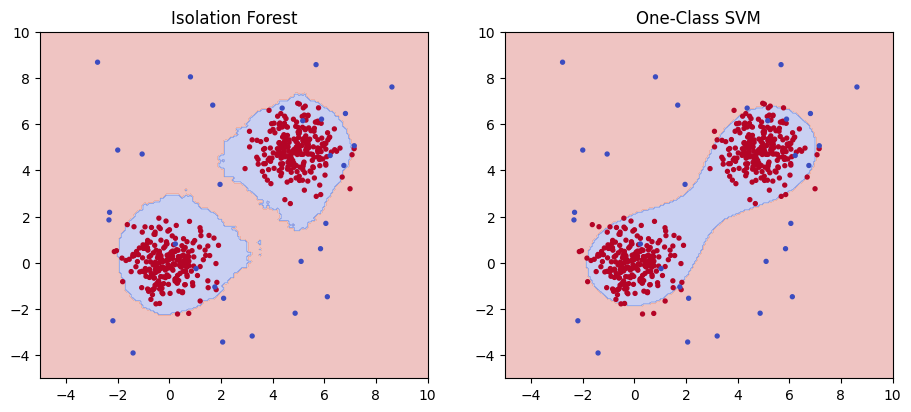

In [10]:
gx, gy = np.meshgrid(np.linspace(-5, 10, 200), np.linspace(-5, 10, 200)); G = np.c_[gx.ravel(), gy.ravel()]
sc = StandardScaler().fit(Xn)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (n, Z) in zip(ax, [("Isolation Forest", iso.predict(G)), ("One-Class SVM", oc.predict(sc.transform(G)))]):
    a.contourf(gx, gy, Z.reshape(gx.shape), alpha=.3, cmap="coolwarm_r"); a.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8); a.set_title(n)
plt.show()

**Kesimpulan:** tidak ada detektor yang selalu menang. Coba beberapa metode, bandingkan dengan metrik yang cocok untuk kelas tidak seimbang,
dan libatkan pengetahuan domain sebelum menghapus data yang dianggap anomali.